# Incremental Data Loading Physics

Full reloads are simple but get slower and more expensive as data grows. **Incremental loading** processes only what changed. It introduces new problems: how do you know what changed, how do you avoid duplicates when a job runs twice, and what about late or deleted records?

**After this lesson you can:**

1. Load incrementally with a high-water mark and compare the cost with full reloads.
2. Make loads idempotent with `MERGE` / upserts and delete-insert by partition.
3. Apply change data capture (CDC) events: inserts, updates and deletes.
4. Handle late-arriving data with a lookback window.

**Data:** NYC taxi trips, January–February 2024 (simulated as daily deliveries), in DuckDB.

In [1]:
import contextlib
import io
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.mkdtemp())

@contextlib.contextmanager
def quiet():
    """Collect the verbose log output of a tool (stderr) instead of printing it in the notebook."""
    buf = io.StringIO()
    with contextlib.redirect_stderr(buf):
        yield buf

wh = duckdb.connect(str(WORK / "incremental.duckdb"))
wh.execute("SET enable_progress_bar = false")              # no progress widget in the notebook output
FILES = [str(datasets.taxi(m)) for m in ["2024-01", "2024-02"]]
wh.execute(f"""
CREATE OR REPLACE VIEW source_trips AS
SELECT row_number() OVER (ORDER BY tpep_pickup_datetime, tpep_dropoff_datetime, PULocationID, DOLocationID, total_amount) AS trip_id,
       tpep_pickup_datetime AS pickup_at, tpep_dropoff_datetime AS dropoff_at, PULocationID AS zone_id, total_amount,
       tpep_dropoff_datetime AS updated_at                -- the source system's "last modified" timestamp
FROM read_parquet({FILES})
WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-03-01' AND fare_amount BETWEEN 3 AND 500
""")
wh.execute("CREATE OR REPLACE TABLE source_snapshot AS SELECT * FROM source_trips")      # materialise the simulated source once
print(wh.sql("SELECT count(*) AS source_rows, min(pickup_at), max(pickup_at) FROM source_snapshot").df())

   source_rows min(pickup_at)      max(pickup_at)
0      5887088     2024-01-01 2024-02-29 23:59:58


## 1. Full Reload vs High-Water Mark

- **Full reload:** copy everything every run. Simple, always correct, cost grows with total size.
- **High-water mark:** remember the largest `updated_at` already loaded; next run, load only rows above it. Cost grows with the **change**, not with the total.

The simulation runs one job per day over February: each day the source has one more day of data.

targets identical in size after 29 runs: True | full: 66.3 s total | incremental: 18.7 s total


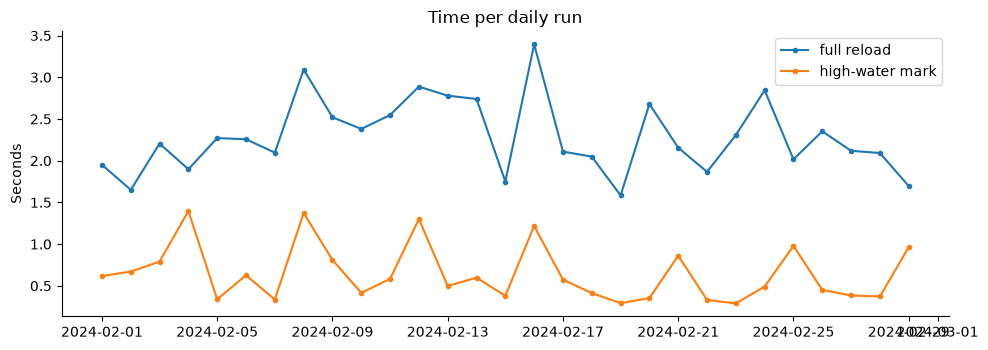

In [2]:
days = pd.date_range("2024-02-01", "2024-02-29")
wh.execute("CREATE OR REPLACE TABLE target_full AS SELECT * FROM source_snapshot WHERE updated_at < '2024-02-01'")
wh.execute("CREATE OR REPLACE TABLE target_inc AS SELECT * FROM source_snapshot WHERE updated_at < '2024-02-01'")
cost = []
for d in days:
    cutoff = (d + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    t = time.perf_counter()
    wh.execute(f"CREATE OR REPLACE TABLE target_full AS SELECT * FROM source_snapshot WHERE updated_at < '{cutoff}'")
    full_s = time.perf_counter() - t
    t = time.perf_counter()
    hwm = wh.sql("SELECT max(updated_at) FROM target_inc").fetchone()[0]
    n_new = wh.execute(f"INSERT INTO target_inc SELECT * FROM source_snapshot WHERE updated_at > '{hwm}' AND updated_at < '{cutoff}'").fetchone()[0]
    inc_s = time.perf_counter() - t
    cost.append({"day": d, "full_s": full_s, "incremental_s": inc_s, "rows_new": n_new})
cost = pd.DataFrame(cost)
same = wh.sql("SELECT (SELECT count(*) FROM target_full) = (SELECT count(*) FROM target_inc)").fetchone()[0]
print(f"targets identical in size after 29 runs: {same} | full: {cost['full_s'].sum():.1f} s total | incremental: {cost['incremental_s'].sum():.1f} s total")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(cost["day"], cost["full_s"], marker=".", label="full reload")
ax.plot(cost["day"], cost["incremental_s"], marker=".", label="high-water mark")
ax.set(title="Time per daily run", ylabel="Seconds")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Idempotency: What If a Job Runs Twice?

Schedulers retry failed jobs, and people re-run jobs by hand. An `INSERT` of "the rows of 15 February" executed twice creates duplicates. Two idempotent patterns:

1. **Upsert / MERGE** on a key: insert new keys, update existing ones.
2. **Delete-insert by partition:** delete the day, insert the day, in one transaction.

In [3]:
def append_day(table, day):
    wh.execute(f"INSERT INTO {table} SELECT * FROM source_snapshot WHERE CAST(pickup_at AS DATE) = DATE '{day}'")

def merge_day(table, day):
    wh.execute(f"""
    MERGE INTO {table} AS t
    USING (SELECT * FROM source_snapshot WHERE CAST(pickup_at AS DATE) = DATE '{day}') AS s
    ON t.trip_id = s.trip_id
    WHEN MATCHED THEN UPDATE SET total_amount = s.total_amount, updated_at = s.updated_at
    WHEN NOT MATCHED THEN INSERT *""")

def delete_insert_day(table, day):
    wh.execute("BEGIN")
    wh.execute(f"DELETE FROM {table} WHERE CAST(pickup_at AS DATE) = DATE '{day}'")
    append_day(table, day)
    wh.execute("COMMIT")

rows = {}
for name, fn in [("plain append", append_day), ("MERGE (upsert)", merge_day), ("delete-insert", delete_insert_day)]:
    tbl = "t_" + name.split()[0].replace("-", "_").lower()
    wh.execute(f"CREATE OR REPLACE TABLE {tbl} AS SELECT * FROM source_snapshot WHERE false")
    for _ in range(2):                                           # the same job runs twice
        fn(tbl, "2024-02-15")
    rows[name] = wh.sql(f"SELECT count(*) FROM {tbl}").fetchone()[0]
truth = wh.sql("SELECT count(*) FROM source_snapshot WHERE CAST(pickup_at AS DATE) = DATE '2024-02-15'").fetchone()[0]
print(f"rows for 15 Feb in the source: {truth:,}")
print({k: f"{v:,}" for k, v in rows.items()})

rows for 15 Feb in the source: 120,948
{'plain append': '241,896', 'MERGE (upsert)': '120,948', 'delete-insert': '120,948'}


## 3. Change Data Capture (CDC)

A high-water mark sees new and **updated** rows (if the source maintains `updated_at`), but never **deletes**: a deleted row simply stops appearing. **CDC** reads the database's change log instead and delivers events: `insert`, `update`, `delete`, with the old and new values (tools: Debezium, M12). The cell applies a batch of CDC events with one `MERGE`.

In [4]:
wh.execute("CREATE OR REPLACE TABLE dim_target AS SELECT trip_id, zone_id, total_amount FROM source_snapshot WHERE pickup_at < '2024-01-01 01:00'")
ids = [r[0] for r in wh.sql("SELECT trip_id FROM dim_target ORDER BY trip_id LIMIT 3").fetchall()]
cdc = pd.DataFrame([
    {"op": "u", "trip_id": ids[0], "zone_id": 132, "total_amount": 99.0, "lsn": 1},     # fare corrected
    {"op": "d", "trip_id": ids[1], "zone_id": None, "total_amount": None, "lsn": 2},     # trip deleted (test record)
    {"op": "c", "trip_id": 10**9, "zone_id": 161, "total_amount": 25.5, "lsn": 3},      # new trip
    {"op": "u", "trip_id": ids[0], "zone_id": 132, "total_amount": 101.0, "lsn": 4},    # corrected again: latest event wins
])
wh.register("cdc_batch", cdc)
before = wh.sql("SELECT count(*), sum(total_amount) FROM dim_target").fetchone()
wh.execute("""
MERGE INTO dim_target AS t
USING (SELECT * FROM cdc_batch QUALIFY row_number() OVER (PARTITION BY trip_id ORDER BY lsn DESC) = 1) AS s   -- latest event per key
ON t.trip_id = s.trip_id
WHEN MATCHED AND s.op = 'd' THEN DELETE
WHEN MATCHED THEN UPDATE SET zone_id = s.zone_id, total_amount = s.total_amount
WHEN NOT MATCHED AND s.op <> 'd' THEN INSERT (trip_id, zone_id, total_amount) VALUES (s.trip_id, s.zone_id, s.total_amount)
""")
after = wh.sql("SELECT count(*), sum(total_amount) FROM dim_target").fetchone()
print(f"rows {before[0]} -> {after[0]} (one delete, one insert)")
print(wh.sql(f"SELECT * FROM dim_target WHERE trip_id IN ({ids[0]}, {ids[1]}, {10**9})").df())

rows 6500 -> 6500 (one delete, one insert)
      trip_id  zone_id  total_amount
0           1      132         101.0
1  1000000000      161          25.5


The batch contained two updates for the same trip; only the **latest** (by log sequence number, `lsn`) may win. Applying events out of order is one of the classic CDC bugs.

## 4. Late-Arriving Data and Lookback Windows

Some records arrive days late (a taxi meter uploads after reconnecting). A high-water mark on **event time** would skip them forever. Two remedies: use the **arrival** time (`updated_at`, `_loaded_at`) as the cursor, or re-process a **lookback window** (for example the last 3 days) with an idempotent pattern.

In [5]:
rng = np.random.default_rng(42)
late = wh.sql("SELECT * FROM source_snapshot WHERE CAST(pickup_at AS DATE) = DATE '2024-02-10' USING SAMPLE 500 ROWS (reservoir, 1)").df()
on_time = wh.sql("SELECT count(*) FROM source_snapshot WHERE CAST(pickup_at AS DATE) = DATE '2024-02-10'").fetchone()[0] - len(late)

def daily_counts(lookback_days: int) -> int:
    """Daily jobs run from 10 to 14 Feb. Each run recomputes the days in [run_day - lookback, run_day] (idempotently).
    500 trips of 10 Feb arrive late, on 13 Feb."""
    value = None
    for run_day in range(10, 15):
        if run_day - lookback_days <= 10 <= run_day:            # is 10 Feb inside this run's window?
            value = on_time + (len(late) if run_day >= 13 else 0)
    return value

truth = on_time + len(late)
for lb in [0, 1, 3]:
    print(f"lookback {lb} day(s): trips for 10 Feb = {daily_counts(lb):,} (true total {truth:,})")

lookback 0 day(s): trips for 10 Feb = 109,996 (true total 110,006)
lookback 1 day(s): trips for 10 Feb = 109,996 (true total 110,006)
lookback 3 day(s): trips for 10 Feb = 110,006 (true total 110,006)


Without a lookback, the late records are never counted; a 3-day lookback catches records up to three days late, at the price of recomputing three partitions per run.

| Pattern | Good for | Watch out |
| :--- | :--- | :--- |
| full reload | small tables, dimensions | cost grows with size |
| high-water mark (append) | append-only events | duplicates on re-runs, misses updates/deletes |
| MERGE on a key | updates, idempotent re-runs | needs a reliable key |
| delete-insert by partition | daily/hourly facts | partition must be complete |
| CDC | full fidelity incl. deletes | ordering, schema changes, tooling |
| lookback window | late data | extra compute |

*Insight: Make every load idempotent first (MERGE or delete-insert), then make it incremental. Choose the cursor by arrival time, not event time, handle deletes explicitly (CDC or periodic reconciliation), and add a lookback window for late data.*

## Real-World Use Case or Analogy

Incremental loading is like **updating a bank statement**: you add only the new transactions since the last statement (high-water mark), you must not add the same transaction twice when the printer jams and restarts (idempotency), cancelled transactions must disappear (deletes), and transactions dated last week can still appear today (late data).

Payment providers, e-commerce platforms and IoT systems all load incrementally; most "the numbers changed overnight" incidents trace back to one of these four problems.